# Step 4: Rolling validation, calibration, lead time, sensitivity
Run Steps 1 to 3 first. Needs `monthly_panel_with_hormuz_state.csv` and `hormuz_daily_state.csv` in your `Dataset` folder.

In [1]:
import pandas as pd, numpy as np
from google.colab import drive
drive.mount('/content/drive')
BASE = '/content/drive/MyDrive/My Work/Research/AI+ BBA/Supply Chain_GNN/Dataset'

Mounted at /content/drive


## 1. Setup: panel, features, labels, models

In [2]:
import statsmodels.api as sm
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
import matplotlib.pyplot as plt

p = pd.read_csv(f"{BASE}/monthly_panel_with_hormuz_state.csv")
p["month"] = pd.PeriodIndex(p["month"], freq="M"); p = p.set_index("month").sort_index()
p = p.loc[:"2026-09"]
FEATS = ["oni_lag1", "oni_chg3", "nino34_lag1", "brent_ret1", "brent_ret3", "brent_z12", "gscpi_lag1", "gscpi_chg3"]

def make_label(rise, h):
    fut = pd.concat([p["gscpi"].shift(-k) - p["gscpi"] for k in range(1, h + 1)], axis=1).max(axis=1)
    return (fut >= rise).astype(float).where(p["gscpi"].shift(-h).notna())

def logit(): return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))
def gboost(): return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150, random_state=0)

# structural (causal-aware) model from Step 3
d = pd.DataFrame({"g": p["gscpi"], "lb": np.log(p["brent"]), "oni": p["oni"]})
d["dg"] = d["g"].diff(); d["db"] = d["lb"].diff(); d["oni_l1"] = d["oni"].shift(1)
d["dg_next"] = d["dg"].shift(-1); d["db_next"] = d["db"].shift(-1)
GC, BC = ["dg", "g", "db", "oni_l1"], ["db", "dg", "oni_l1"]
rng = np.random.default_rng(0)
def fit_struct(end):
    s = d.loc["1999-01":end].dropna(subset=GC + ["dg_next", "db_next"])
    mg = sm.OLS(s["dg_next"], sm.add_constant(s[GC])).fit(); mb = sm.OLS(s["db_next"], sm.add_constant(s[BC])).fit()
    return mg, mb, np.column_stack([mg.resid.values, mb.resid.values])
def struct_prob(row, h, rise, mg, mb, res, n=250):
    idx = rng.integers(0, len(res), size=(n, h)); G = np.full(n, row["g"]); DG = np.full(n, row["dg"]); DB = np.full(n, row["db"])
    best = np.full(n, -np.inf)
    for k in range(h):
        e = res[idx[:, k]]
        dgn = mg.params["const"] + mg.params["dg"] * DG + mg.params["g"] * G + mg.params["db"] * DB + mg.params["oni_l1"] * row["oni_l1"] + e[:, 0]
        dbn = mb.params["const"] + mb.params["db"] * DB + mb.params["dg"] * DG + mb.params["oni_l1"] * row["oni_l1"] + e[:, 1]
        G = G + dgn; DG, DB = dgn, dbn; best = np.maximum(best, G - row["g"])
    return float((best >= rise).mean())

## 2. Rolling-origin (walk-forward) predictions

In [3]:
def rolling(rise, h, first_year=2012, last_year=2025, feats=FEATS, models=("logistic", "grad_boost", "causal_structural")):
    y = make_label(rise, h); out = []
    for yr in range(first_year, last_year + 1):
        cutoff = pd.Period(f"{yr-1}-12", freq="M") - h            # last training month whose label is fully known
        tr = p.index[(p.index >= "1999-01") & (p.index <= cutoff)]; tr = tr[y.reindex(tr).notna().values]
        te = p.index[(p.index >= f"{yr}-01") & (p.index <= f"{yr}-12")]; te = te[y.reindex(te).notna().values]
        ytr = y.loc[tr]
        if ytr.sum() < 5 or ytr.nunique() < 2 or len(te) == 0: continue
        preds = {}
        for name, mk in (("logistic", logit), ("grad_boost", gboost)):
            if name in models:
                m = mk().fit(p.loc[tr, feats], ytr); preds[name] = m.predict_proba(p.loc[te, feats])[:, 1]
        if "causal_structural" in models:
            mg, mb, res = fit_struct(pd.Period(f"{yr-1}-11", freq="M"))
            preds["causal_structural"] = [struct_prob(d.loc[t], h, rise, mg, mb, res) if d.loc[t, ["dg", "g", "db", "oni_l1"]].notna().all() else np.nan for t in te]
        for name, pr in preds.items():
            out.append(pd.DataFrame({"month": te, "h": h, "rise": rise, "model": name, "y": y.loc[te].values, "p": pr, "base_rate": ytr.mean()}))
    return pd.concat(out, ignore_index=True)

pred = pd.concat([rolling(0.5, h) for h in (1, 2, 3)], ignore_index=True).dropna(subset=["p"])
pred.to_csv(f"{BASE}/rolling_predictions.csv", index=False)
print(pred.groupby(["h", "model"]).size().unstack())

model  causal_structural  grad_boost  logistic
h                                             
1                    168         168       168
2                    168         168       168
3                    168         168       168


## 3. Metrics: discrimination and calibration

 h             model   n  pos_rate   auc  avg_precision  brier  brier_skill_vs_climatology   ece
 1 causal_structural 168      0.09 0.403          0.106  0.086                      -0.044 0.063
 1        grad_boost 168      0.09 0.514          0.103  0.093                      -0.123 0.099
 1          logistic 168      0.09 0.576          0.130  0.084                      -0.021 0.055
 2 causal_structural 168      0.18 0.499          0.208  0.158                      -0.061 0.089
 2        grad_boost 168      0.18 0.467          0.199  0.182                      -0.222 0.171
 2          logistic 168      0.18 0.498          0.204  0.161                      -0.080 0.112
 3 causal_structural 168      0.23 0.496          0.257  0.201                      -0.105 0.132
 3        grad_boost 168      0.23 0.476          0.253  0.220                      -0.213 0.165
 3          logistic 168      0.23 0.445          0.246  0.208                      -0.147 0.145


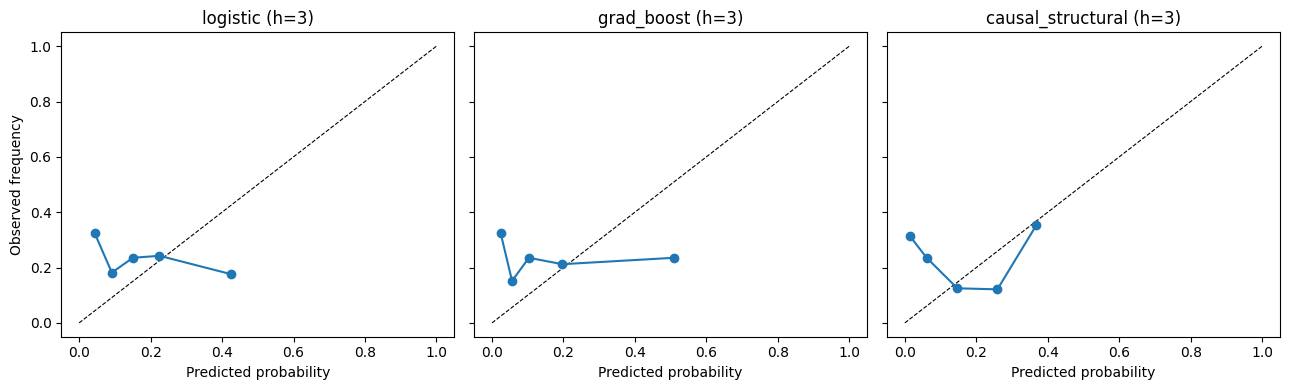

In [4]:
def ece(y, pr, bins=5):
    q = pd.qcut(pr, bins, duplicates="drop"); g = pd.DataFrame({"y": y, "p": pr, "q": q}).groupby("q", observed=True)
    return float((g.size() / len(y) * (g["y"].mean() - g["p"].mean()).abs()).sum())
rows = []
for (h, mname), g in pred.groupby(["h", "model"]):
    bs = brier_score_loss(g.y, g.p); bs_clim = brier_score_loss(g.y, g.base_rate)
    rows.append(dict(h=h, model=mname, n=len(g), pos_rate=round(g.y.mean(), 2), auc=round(roc_auc_score(g.y, g.p), 3),
                     avg_precision=round(average_precision_score(g.y, g.p), 3), brier=round(bs, 3),
                     brier_skill_vs_climatology=round(1 - bs / bs_clim, 3), ece=round(ece(g.y, g.p), 3)))
metrics = pd.DataFrame(rows); print(metrics.to_string(index=False)); metrics.to_csv(f"{BASE}/rolling_metrics.csv", index=False)

fig, axs = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, mname in zip(axs, ["logistic", "grad_boost", "causal_structural"]):
    g = pred[(pred.h == 3) & (pred.model == mname)]
    r = g.assign(q=pd.qcut(g.p, 5, duplicates="drop")).groupby("q", observed=True).agg(pred=("p", "mean"), obs=("y", "mean"))
    ax.plot([0, 1], [0, 1], "k--", lw=0.8); ax.plot(r["pred"], r["obs"], "o-"); ax.set_title(f"{mname} (h=3)"); ax.set_xlabel("Predicted probability")
axs[0].set_ylabel("Observed frequency"); fig.tight_layout(); fig.savefig(f"{BASE}/reliability_h3.png", dpi=150); plt.show()

## 4. Lead time

In [5]:
# Event = a month where GSCPI has risen >= 0.5 above the level 3 months earlier (first month of each cluster).
g3 = p["gscpi"]; cand = g3[(g3 - g3.shift(3)) >= 0.5].index
events = [m for i, m in enumerate(cand) if i == 0 or (m - cand[i - 1]).n > 3]
events = [e for e in events if e >= pd.Period("2012-01", freq="M")]
print("number of events (2012 onward):", len(events))
lead_rows = []
for mname in ["logistic", "grad_boost", "causal_structural"]:
    g = pred[(pred.h == 3) & (pred.model == mname)].set_index("month")
    thr = g["p"].quantile(0.80)                      # alarm threshold = top 20% of predicted risk (about 20% of months)
    alarm = g["p"] >= thr
    leads = []
    for e in events:
        win = [e - k for k in range(1, 7) if (e - k) in alarm.index]
        hit = [m for m in win if alarm.loc[m]]
        leads.append((e - min(hit)).n if hit else np.nan)
    far = float(alarm[g["y"] == 0].mean())
    lead_rows.append(dict(model=mname, alarm_threshold=round(float(thr), 3), events=len(events),
                          detected=int(np.sum(~np.isnan(leads))), detection_rate=round(float(np.mean(~np.isnan(leads))), 2),
                          median_lead_months=float(np.nanmedian(leads)) if np.any(~np.isnan(leads)) else np.nan,
                          false_alarm_rate=round(far, 2)))
lead = pd.DataFrame(lead_rows); print(lead.to_string(index=False)); lead.to_csv(f"{BASE}/lead_time.csv", index=False)

number of events (2012 onward): 12
            model  alarm_threshold  events  detected  detection_rate  median_lead_months  false_alarm_rate
         logistic            0.257      12         4            0.33                 4.0              0.22
       grad_boost            0.291      12         6            0.50                 3.5              0.20
causal_structural            0.298      12         5            0.42                 3.0              0.17


## 5. Sensitivity and ablation

In [6]:
sens = []
for rise in (0.3, 0.5, 0.75):
    pr_ = pred if rise == 0.5 else rolling(rise, 3, models=("logistic", "grad_boost", "causal_structural"))
    pr_ = pr_[pr_.h == 3] if rise == 0.5 else pr_.dropna(subset=["p"])
    for mname, g in pr_.groupby("model"):
        if g.y.nunique() > 1: sens.append(dict(test="label threshold", setting=f"rise>={rise}", model=mname, pos_rate=round(g.y.mean(), 2), auc=round(roc_auc_score(g.y, g.p), 3)))
nono = [f for f in FEATS if not f.startswith(("oni", "nino"))]; nobr = [f for f in FEATS if not f.startswith("brent")]
for lab, fs in {"all features": FEATS, "without ENSO": nono, "without Brent": nobr}.items():
    r = rolling(0.5, 3, feats=fs, models=("logistic", "grad_boost")).dropna(subset=["p"])
    for mname, g in r.groupby("model"):
        sens.append(dict(test="ablation (h=3)", setting=lab, model=mname, pos_rate=round(g.y.mean(), 2), auc=round(roc_auc_score(g.y, g.p), 3)))
sens = pd.DataFrame(sens); print(sens.to_string(index=False)); sens.to_csv(f"{BASE}/sensitivity.csv", index=False)

hz = pd.read_csv(f"{BASE}/hormuz_daily_state.csv", parse_dates=["date"]).set_index("date")
hrows = []
for lo, hi in [(0.4, 0.15), (0.5, 0.20), (0.6, 0.25)]:
    below = hz["ratio"] < hi; run = below.rolling(2).sum() == 2
    onset = run[run].index.min()
    hrows.append(dict(thresholds=f"{lo}/{hi}", first_state3_date=str(onset.date()), days_state3=int(below["2026-03-01":].sum()),
                      first_state2_or_worse=str(hz.index[(hz["ratio"] < lo)][hz.index[(hz["ratio"] < lo)] > "2026-02-15"].min().date())))
hsens = pd.DataFrame(hrows); print(hsens.to_string(index=False)); hsens.to_csv(f"{BASE}/hormuz_threshold_sensitivity.csv", index=False)

           test       setting             model  pos_rate   auc
label threshold     rise>=0.3 causal_structural      0.39 0.579
label threshold     rise>=0.3        grad_boost      0.39 0.515
label threshold     rise>=0.3          logistic      0.39 0.528
label threshold     rise>=0.5 causal_structural      0.23 0.496
label threshold     rise>=0.5        grad_boost      0.23 0.476
label threshold     rise>=0.5          logistic      0.23 0.445
label threshold    rise>=0.75 causal_structural      0.11 0.384
label threshold    rise>=0.75        grad_boost      0.11 0.510
label threshold    rise>=0.75          logistic      0.11 0.408
 ablation (h=3)  all features        grad_boost      0.23 0.476
 ablation (h=3)  all features          logistic      0.23 0.445
 ablation (h=3)  without ENSO        grad_boost      0.23 0.475
 ablation (h=3)  without ENSO          logistic      0.23 0.435
 ablation (h=3) without Brent        grad_boost      0.23 0.453
 ablation (h=3) without Brent          l